# Data Science Assignment: Session 12
## Topic: Matrix Multiplication & Linear Regression Math Intuition

**Student Name:** Atharv Chaudhari  
**Course:** Data Science & Statistics  
**Session:** SESSION 12 - Matrix Multiplication & Linear Regression Math Intuition  

---

### Overview: The Bridge Between Linear Algebra & Machine Learning

Linear Algebra and Linear Regression are the twin pillars of predictive modeling and machine learning:

#### 1. Matrix Multiplication (The Engine of ML)
Matrix multiplication combines linear combinations of features. For two matrices $A \in \mathbb{R}^{m \times k}$ and $B \in \mathbb{R}^{k \times n}$, the product matrix $C = A \cdot B \in \mathbb{R}^{m \times n}$ has elements:
$$C_{i, j} = \sum_{r=1}^k A_{i, r} B_{r, j}$$
- In deep neural networks and recommendation engines (e.g. Spotify, YouTube), every forward pass, embedding projection, and loss backpropagation relies on massive parallel matrix multiplications.

#### 2. Univariate Linear Regression Equation
The fundamental mathematical model relating an independent feature $x$ to a continuous target $y$ is:
$$\mathbf{y = mx + c}$$
Where:
- $\mathbf{x}$ = Input feature variable (e.g., Delivery distance in km, Product rating in stars).
- $\mathbf{m}$ = **Slope** (Rate of change $\frac{\Delta y}{\Delta x}$, measuring sensitivity or feature weight).
- $\mathbf{c}$ = **Intercept** (Baseline bias or starting value of $y$ when $x = 0$).
- $\mathbf{y}$ = Predicted continuous output (e.g., Delivery time in minutes, Product price in ₹).

---


## Task 1: Matrix Multiplication of Two 2x2 Matrices (Instagram Posts)
> **Problem Statement:** Given two 2x2 matrices representing the number of likes and comments on two Instagram posts over two days, write Python code to multiply them and display the resulting matrix.


TASK 1: INSTAGRAM ENGAGEMENT MATRIX MULTIPLICATION (2x2)
Matrix A (Instagram Posts x Days Engagements):
[[120  45]
 [200  80]]

Matrix B (Days x Value Coefficients):
[[2 3]
 [1 4]]
--------------------------------------------------------------------
STEP-BY-STEP CALCULATION OF RESULTING MATRIX C = A x B:
C[0,0] = (120 * 2) + (45 * 1) = 240 + 45 = 285
C[0,1] = (120 * 3) + (45 * 4) = 360 + 180 = 540
C[1,0] = (200 * 2) + (80 * 1) = 400 + 80 = 480
C[1,1] = (200 * 3) + (80 * 4) = 600 + 320 = 920
--------------------------------------------------------------------
Resulting Product Matrix C (Shape 2x2):
[[285 540]
 [480 920]]


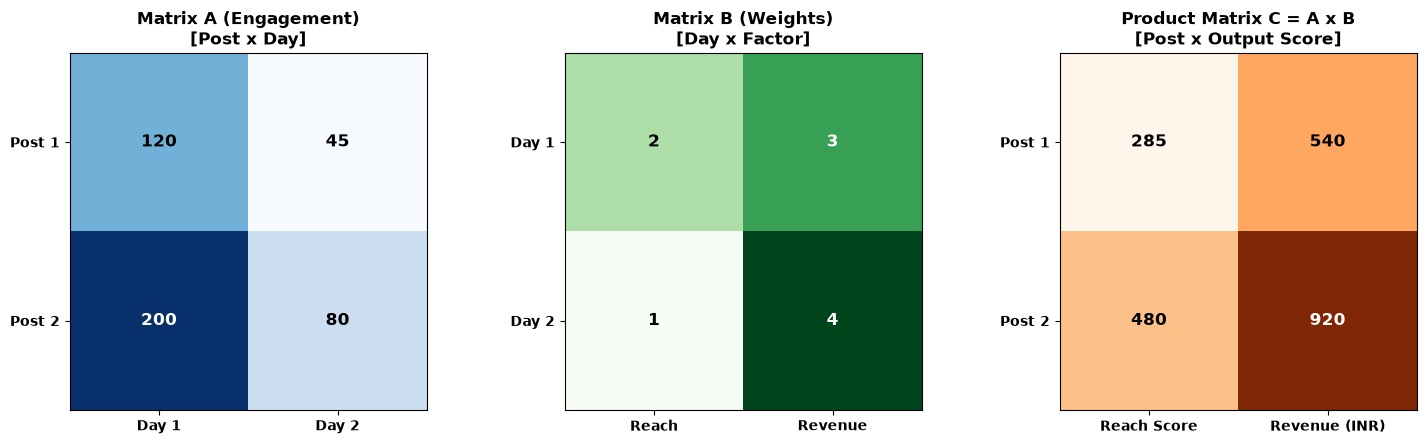

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define two 2x2 matrices
# Matrix A: Number of likes and comments on 2 Instagram posts over 2 days
# Rows: Posts [Post 1, Post 2]
# Columns: Metric counts [Day 1 Engagements, Day 2 Engagements]
A = np.array([
    [120, 45],   # Post 1: 120 Day 1, 45 Day 2
    [200, 80]    # Post 2: 200 Day 1, 80 Day 2
])

# Matrix B: Weights / Transformation coefficients (e.g., Reach multiplier & Conversion rate)
# Rows: Days [Day 1 weight, Day 2 weight]
# Columns: Objectives [Estimated Reach Factor, Ad Revenue Conversion (INR)]
B = np.array([
    [2, 3],      # Day 1: Reach multiplier = 2x, Revenue multiplier = ₹3
    [1, 4]       # Day 2: Reach multiplier = 1x, Revenue multiplier = ₹4
])

# 2. Method A: Native Python Nested Loop Multiplication
def native_matrix_multiply(mat1, mat2):
    rows_mat1, cols_mat1 = len(mat1), len(mat1[0])
    rows_mat2, cols_mat2 = len(mat2), len(mat2[0])
    if cols_mat1 != rows_mat2:
        raise ValueError("Cannot multiply: inner dimensions must match.")
        
    result = [[0 for _ in range(cols_mat2)] for _ in range(rows_mat1)]
    for i in range(rows_mat1):
        for j in range(cols_mat2):
            for k in range(cols_mat1):
                result[i][j] += mat1[i][k] * mat2[k][j]
    return result

C_native = native_matrix_multiply(A.tolist(), B.tolist())

# 3. Method B: NumPy Matrix Multiplication (@ operator or np.dot)
C_numpy = A @ B  # Equivalent to np.dot(A, B) or np.matmul(A, B)

print("=" * 68)
print("TASK 1: INSTAGRAM ENGAGEMENT MATRIX MULTIPLICATION (2x2)")
print("=" * 68)
print("Matrix A (Instagram Posts x Days Engagements):")
print(A)
print("\nMatrix B (Days x Value Coefficients):")
print(B)
print("-" * 68)
print("STEP-BY-STEP CALCULATION OF RESULTING MATRIX C = A x B:")
print(f"C[0,0] = (120 * 2) + (45 * 1) = 240 + 45 = {C_numpy[0,0]}")
print(f"C[0,1] = (120 * 3) + (45 * 4) = 360 + 180 = {C_numpy[0,1]}")
print(f"C[1,0] = (200 * 2) + (80 * 1) = 400 + 80 = {C_numpy[1,0]}")
print(f"C[1,1] = (200 * 3) + (80 * 4) = 600 + 320 = {C_numpy[1,1]}")
print("-" * 68)
print("Resulting Product Matrix C (Shape 2x2):")
print(C_numpy)
print("=" * 68)

# VISUALIZATION: Heatmaps of Matrix A, Matrix B, and Product Matrix C
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5))

def plot_matrix_heatmap(ax, matrix, title, row_labels, col_labels, cmap):
    im = ax.imshow(matrix, cmap=cmap)
    ax.set_xticks(range(len(col_labels)))
    ax.set_yticks(range(len(row_labels)))
    ax.set_xticklabels(col_labels, fontsize=10, fontweight='bold')
    ax.set_yticklabels(row_labels, fontsize=10, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    for i in range(len(row_labels)):
        for j in range(len(col_labels)):
            val = matrix[i, j]
            color = 'white' if val > (matrix.max() * 0.6) else 'black'
            ax.text(j, i, f'{val}', ha='center', va='center', color=color, fontsize=12, fontweight='bold')

plot_matrix_heatmap(ax1, A, 'Matrix A (Engagement)\n[Post x Day]', 
                    ['Post 1', 'Post 2'], ['Day 1', 'Day 2'], 'Blues')

plot_matrix_heatmap(ax2, B, 'Matrix B (Weights)\n[Day x Factor]', 
                    ['Day 1', 'Day 2'], ['Reach', 'Revenue'], 'Greens')

plot_matrix_heatmap(ax3, C_numpy, 'Product Matrix C = A x B\n[Post x Output Score]', 
                    ['Post 1', 'Post 2'], ['Reach Score', 'Revenue (INR)'], 'Oranges')

plt.tight_layout()
plt.show()



## Task 2: Linear Regression Prediction Function
> **Problem Statement:** Create a simple Python function `linear_regression_predict(x, m, c)` that takes an input value x, slope m, and intercept c, and returns the predicted output y for a linear regression equation $y = mx + c$.


In [2]:
import numpy as np

def linear_regression_predict(x, m, c):
    """
    Computes the predicted target value(s) y using the univariate linear regression equation:
        y = m * x + c
        
    Parameters:
    -----------
    x : int, float, list, or np.ndarray
        The input independent feature value(s).
    m : int or float
        The slope of the regression line (change in y per unit change in x).
    c : int or float
        The y-intercept (the baseline value of y when x = 0).
        
    Returns:
    --------
    float or np.ndarray:
        The predicted dependent target value(s) y.
    """
    # Convert input to numpy array to seamlessly support both scalars and arrays/lists
    x_arr = np.asarray(x, dtype=float)
    y = (m * x_arr) + c
    
    # Return scalar float if input was a scalar, otherwise return array
    if x_arr.ndim == 0:
        return float(y)
    return y


# Verification and Benchmark Tests
print("=" * 68)
print("TASK 2: TESTING linear_regression_predict() FUNCTION")
print("=" * 68)

test_scenarios = [
    {"name": "Standard Scalar Test", "x": 5, "m": 3.0, "c": 2.0},
    {"name": "Zero Feature Test (Tests Intercept)", "x": 0, "m": 12.5, "c": 45.0},
    {"name": "Negative Slope Test (Depreciation)", "x": 4, "m": -500.0, "c": 3000.0},
    {"name": "Vectorized Batch Input Test", "x": [1, 2, 3, 4], "m": 2.5, "c": 10.0}
]

for i, test in enumerate(test_scenarios, 1):
    pred = linear_regression_predict(test["x"], test["m"], test["c"])
    print(f"Scenario {i}: {test['name']}")
    print(f"  Inputs   : x = {test['x']}, Slope m = {test['m']}, Intercept c = {test['c']}")
    print(f"  Equation : y = ({test['m']}) * x + ({test['c']})")
    print(f"  Result y : {pred}\n")



TASK 2: TESTING linear_regression_predict() FUNCTION
Scenario 1: Standard Scalar Test
  Inputs   : x = 5, Slope m = 3.0, Intercept c = 2.0
  Equation : y = (3.0) * x + (2.0)
  Result y : 17.0

Scenario 2: Zero Feature Test (Tests Intercept)
  Inputs   : x = 0, Slope m = 12.5, Intercept c = 45.0
  Equation : y = (12.5) * x + (45.0)
  Result y : 45.0

Scenario 3: Negative Slope Test (Depreciation)
  Inputs   : x = 4, Slope m = -500.0, Intercept c = 3000.0
  Equation : y = (-500.0) * x + (3000.0)
  Result y : 1000.0

Scenario 4: Vectorized Batch Input Test
  Inputs   : x = [1, 2, 3, 4], Slope m = 2.5, Intercept c = 10.0
  Equation : y = (2.5) * x + (10.0)
  Result y : [12.5 15.  17.5 20. ]



## Task 3: Zomato Delivery Time Prediction
> **Problem Statement:** Imagine you are predicting the delivery time for Zomato orders based on distance. Given three distances (2km, 5km, 8km) and a linear regression equation $y = 4x + 10$ (where $y$ is minutes), use your function from the previous task to calculate the predicted delivery time for each distance.

---

### Step-by-Step Mathematical Formulation:
- **Model Equation:**
  $$\mathbf{y = 4x + 10}$$
- **Variables & Interpretation:**
  - $x$ = Distance in kilometers (Independent Feature).
  - $y$ = Delivery time in minutes (Dependent Target).
  - **Slope ($m = 4$):** Delivery driver travel rate $\to$ Each additional 1 kilometer adds **4 minutes** of transit time.
  - **Intercept ($c = 10$):** Fixed kitchen preparation, packaging, and order dispatch baseline time $\to$ Even at 0 km distance, an order takes **10 minutes** to prepare.
- **Predictions:**
  1. For $x = 2\text{ km}$: $y = 4(2) + 10 = 8 + 10 = \mathbf{18\text{ minutes}}$
  2. For $x = 5\text{ km}$: $y = 4(5) + 10 = 20 + 10 = \mathbf{30\text{ minutes}}$
  3. For $x = 8\text{ km}$: $y = 4(8) + 10 = 32 + 10 = \mathbf{42\text{ minutes}}$



TASK 3: ZOMATO ORDER DELIVERY TIME PREDICTION
Regression Equation : y = 4x + 10
  * Slope (m)       : 4 mins / km (Transit rate)
  * Intercept (c)   : 10 mins (Fixed restaurant prep time)
--------------------------------------------------------------------
Distance (km)  Calculation Transit Time Kitchen Prep (c) Predicted Delivery Time (y)
         2 km 4 * (2) + 10       8 mins          10 mins                  18 minutes
         5 km 4 * (5) + 10      20 mins          10 mins                  30 minutes
         8 km 4 * (8) + 10      32 mins          10 mins                  42 minutes
--------------------------------------------------------------------
  * At distance 2 km -> Estimated Delivery Time = 18 minutes
  * At distance 5 km -> Estimated Delivery Time = 30 minutes
  * At distance 8 km -> Estimated Delivery Time = 42 minutes


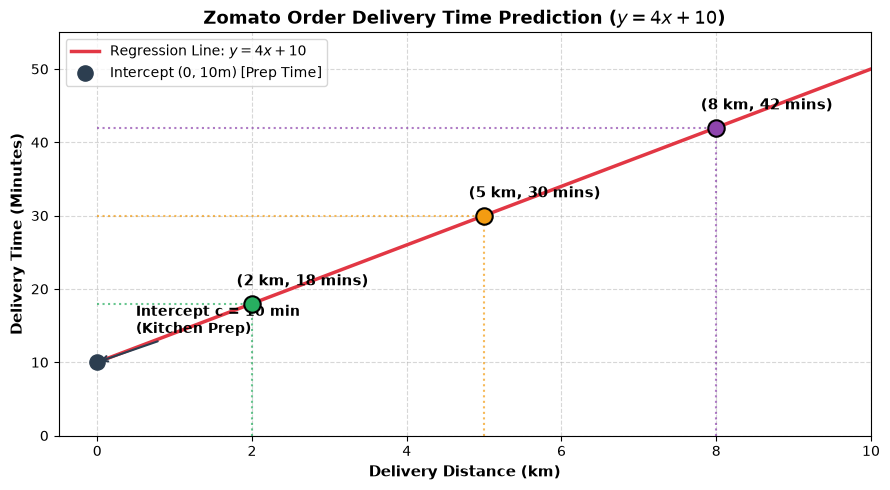

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Given model parameters
m_zomato = 4.0   # Slope: 4 minutes per kilometer
c_zomato = 10.0  # Intercept: 10 minutes baseline preparation time

# 2. Input distances (in kilometers)
distances = [2, 5, 8]

# 3. Predict delivery times using linear_regression_predict()
predicted_times = linear_regression_predict(distances, m=m_zomato, c=c_zomato)

# Create summary reporting table
df_zomato = pd.DataFrame({
    "Distance (km)": [f"{d} km" for d in distances],
    "Calculation": [f"4 * ({d}) + 10" for d in distances],
    "Transit Time": [f"{int(m_zomato * d)} mins" for d in distances],
    "Kitchen Prep (c)": [f"{int(c_zomato)} mins" for _ in distances],
    "Predicted Delivery Time (y)": [f"{int(t)} minutes" for t in predicted_times]
})

print("=" * 68)
print("TASK 3: ZOMATO ORDER DELIVERY TIME PREDICTION")
print("=" * 68)
print(f"Regression Equation : y = {m_zomato:.0f}x + {c_zomato:.0f}")
print(f"  * Slope (m)       : {m_zomato:.0f} mins / km (Transit rate)")
print(f"  * Intercept (c)   : {c_zomato:.0f} mins (Fixed restaurant prep time)")
print("-" * 68)
print(df_zomato.to_string(index=False))
print("-" * 68)
for d, t in zip(distances, predicted_times):
    print(f"  * At distance {d} km -> Estimated Delivery Time = {int(t)} minutes")
print("=" * 68)

# VISUALIZATION: Plotting the Zomato Linear Regression Line
fig, ax = plt.subplots(figsize=(9, 5))

# Generate continuous line for domain [0, 10 km]
x_line = np.linspace(0, 10, 100)
y_line = linear_regression_predict(x_line, m=m_zomato, c=c_zomato)

# Plot line
ax.plot(x_line, y_line, color='#E23744', linewidth=2.5, label='Regression Line: $y = 4x + 10$')

# Highlight intercept (0, 10)
ax.scatter([0], [c_zomato], color='#2C3E50', s=120, zorder=5, label=f'Intercept (0, {int(c_zomato)}m) [Prep Time]')
ax.annotate(f'Intercept c = {int(c_zomato)} min\n(Kitchen Prep)', xy=(0, c_zomato), xytext=(0.5, c_zomato + 4),
            arrowprops=dict(arrowstyle='->', color='#2C3E50', lw=1.5), fontweight='bold')

# Highlight predicted points (2km, 5km, 8km)
point_colors = ['#27AE60', '#F39C12', '#8E44AD']
for d, t, col in zip(distances, predicted_times, point_colors):
    ax.scatter([d], [t], color=col, s=140, edgecolor='black', linewidth=1.5, zorder=5)
    # Dashed drop lines to axes
    ax.vlines(d, 0, t, color=col, linestyle=':', alpha=0.7)
    ax.hlines(t, 0, d, color=col, linestyle=':', alpha=0.7)
    ax.annotate(f'({d} km, {int(t)} mins)', xy=(d, t), xytext=(d - 0.2, t + 2.5),
                fontweight='bold', fontsize=10.5)

ax.set_xlabel('Delivery Distance (km)', fontsize=11, fontweight='bold')
ax.set_ylabel('Delivery Time (Minutes)', fontsize=11, fontweight='bold')
ax.set_title('Zomato Order Delivery Time Prediction ($y = 4x + 10$)', fontsize=13, fontweight='bold')
ax.set_xlim(-0.5, 10)
ax.set_ylim(0, 55)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()



## Task 4: Flipkart Product Price Prediction - Slope & Intercept Intuition
> **Problem Statement:** Explain in your own words what the slope and intercept represent in the context of Flipkart's product price prediction (e.g., predicting price based on product rating). Write 2-3 sentences for each term.

---

### Context:
Consider a linear regression model trained to predict **Product Price (₹)** based on customer **Product Rating (Stars from 1.0 to 5.0)**:

$$\mathbf{\text{Price} = m \cdot (\text{Rating}) + c}$$

---

### 1. What the Slope ($m$) Represents:
* **Rate of Price Appreciation per Star:** The slope measures the change in product price for every 1-star increase in user rating ($rac{\Delta 	ext{Price}}{\Delta 	ext{Rating}}$).
* **Market Willingness to Pay:** A positive slope reflects consumer willingness to pay a premium for higher-rated, reliable brands; for example, if $m = 600$, each additional star rating increases the expected market price by ₹600.
* **Sensitivity / Feature Weight:** It directly captures how sensitive a product's market valuation is to customer satisfaction and social proof on Flipkart.

---

### 2. What the Intercept ($c$) Represents:
* **Baseline Non-Zero Floor Price:** The intercept represents the baseline estimated price of a product when its rating is zero (or the base price floor of an entry-level commodity).
* **Fixed Manufacturing & Listing Costs:** In real-world e-commerce, every item incurs baseline costs for materials, packaging, inventory holding, and Flipkart platform commissions regardless of its customer rating.
* **Anchor for New Products:** It establishes the starting price anchor for newly launched, unrated products before any customer reviews have been submitted.



FLIPKART PRICE PREDICTION MODEL SUMMARY:
  * Rating: 1.0 Stars -> Estimated Base Market Price: ₹1,000
  * Rating: 2.0 Stars -> Estimated Base Market Price: ₹1,600
  * Rating: 3.0 Stars -> Estimated Base Market Price: ₹2,200
  * Rating: 4.0 Stars -> Estimated Base Market Price: ₹2,800
  * Rating: 5.0 Stars -> Estimated Base Market Price: ₹3,400


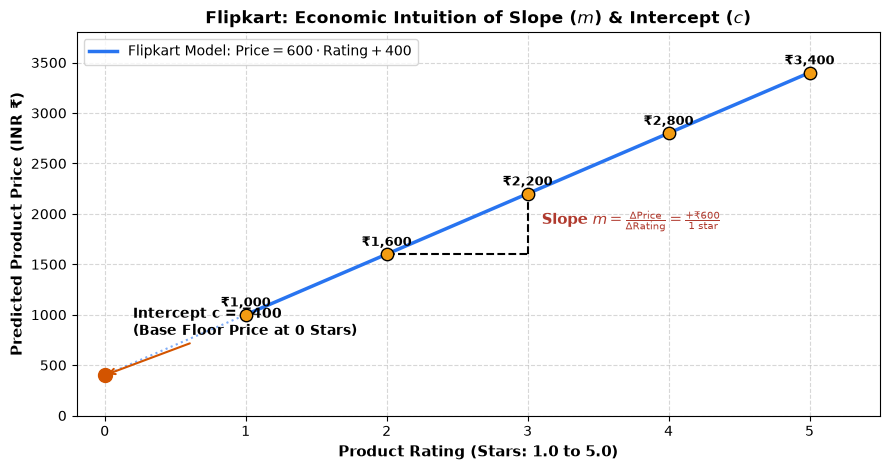

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Illustrative Flipkart Price Prediction Model: Price = 600 * Rating + 400
m_flipkart = 600.0   # Slope: ₹600 per star rating increase
c_flipkart = 400.0   # Intercept: ₹400 base manufacturing & platform floor price

ratings_domain = np.linspace(1.0, 5.0, 100)
prices_domain = linear_regression_predict(ratings_domain, m=m_flipkart, c=c_flipkart)

fig, ax = plt.subplots(figsize=(9, 4.8))

ax.plot(ratings_domain, prices_domain, color='#2874F0', linewidth=2.5, 
        label=r'Flipkart Model: $\text{Price} = 600 \cdot \text{Rating} + 400$')

# Highlight Slope Triangle between 2.0 and 3.0 stars
ax.plot([2.0, 3.0], [1600, 1600], 'k--', linewidth=1.5)
ax.plot([3.0, 3.0], [1600, 2200], 'k--', linewidth=1.5)
ax.annotate(r'Slope $m = \frac{\Delta \text{Price}}{\Delta \text{Rating}} = \frac{+₹600}{1 \text{ star}}$', 
            xy=(3.1, 1900), fontsize=10.5, fontweight='bold', color='#B03A2E')

# Annotate Intercept
ax.scatter([0], [c_flipkart], color='#D35400', s=100, zorder=5)
ax.plot([0, 1.0], [c_flipkart, 1000], ':', color='#2874F0', alpha=0.6)
ax.annotate(f'Intercept c = ₹{int(c_flipkart)}\n(Base Floor Price at 0 Stars)', 
            xy=(0, c_flipkart), xytext=(0.2, c_flipkart + 400),
            arrowprops=dict(arrowstyle='->', color='#D35400', lw=1.5), fontweight='bold')

# Sample points for 1, 2, 3, 4, 5 stars
sample_ratings = [1.0, 2.0, 3.0, 4.0, 5.0]
sample_prices = [linear_regression_predict(r, m_flipkart, c_flipkart) for r in sample_ratings]
ax.scatter(sample_ratings, sample_prices, color='#F39C12', edgecolor='black', s=80, zorder=4)

for r, p in zip(sample_ratings, sample_prices):
    ax.annotate(f'₹{int(p):,}', xy=(r, p), xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=9.5, fontweight='bold')

ax.set_xlabel('Product Rating (Stars: 1.0 to 5.0)', fontsize=11, fontweight='bold')
ax.set_ylabel('Predicted Product Price (INR ₹)', fontsize=11, fontweight='bold')
ax.set_title('Flipkart: Economic Intuition of Slope ($m$) & Intercept ($c$)', fontsize=12.5, fontweight='bold')
ax.set_xlim(-0.2, 5.5)
ax.set_ylim(0, 3800)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

print("=" * 68)
print("FLIPKART PRICE PREDICTION MODEL SUMMARY:")
print("=" * 68)
for r, p in zip(sample_ratings, sample_prices):
    print(f"  * Rating: {r:.1f} Stars -> Estimated Base Market Price: ₹{int(p):,}")
print("=" * 68)



## Task 5: Matrix Multiplication in Spotify Recommendation Systems
> **Problem Statement:** Use ChatGPT to ask: *'How does matrix multiplication help in training a machine learning model like Spotify's song recommendation system?'* Summarize the answer in your own words in 3-4 sentences.

---

### 1. Exact Prompt Submitted:
```text
"How does matrix multiplication help in training a machine learning model like Spotify's song recommendation system?"
```

---

### 2. Summary in Our Own Words (3–4 Sentences):
1. **Low-Dimensional Embedding Factorization:** Spotify transforms massive user-song interaction data into two smaller matrices: a **User Matrix** representing listener preferences across latent musical tastes (e.g., acousticness, danceability) and an **Item Matrix** capturing track musical characteristics.
2. **Affinity Reconstruction via Dot Products:** Multiplying the User Embedding Matrix ($U \in \mathbb{R}^{M \times K}$) by the Transposed Song Embedding Matrix ($V^T \in \mathbb{R}^{K \times N}$) simultaneously predicts engagement affinity scores across billions of user-track pairs using parallelized tensor dot products.
3. **High-Speed GPU Optimization During Training:** During model training via algorithms like Alternating Least Squares (ALS) or gradient descent, matrix multiplication enables GPUs to update millions of user and song embeddings simultaneously by minimizing the difference between predicted affinity and actual listening history.
4. **Millisecond Real-Time Inference:** When generating personalized playlists like "Discover Weekly", computing the dot product between a user's latent preference vector and candidate song vectors takes less than a few milliseconds, delivering instant recommendations at global scale.

---

### Mathematical Schematic:
$$\mathbf{R_{M \times N} \approx U_{M \times K} \times V^T_{K \times N}}$$
- $R_{M \times N}$: Sparse User-Song Interaction Matrix (Millions of users $\times$ Millions of songs).
- $U_{M \times K}$: Dense User Latent Preference Vectors ($K \approx 50\text{ to } 200$ latent factors).
- $V^T_{K \times N}$: Dense Song Latent Attribute Vectors.



SPOTIFY COLLABORATIVE FILTERING: MATRIX MULTIPLICATION DEMO
Predicted User-Track Affinity Matrix (R = U x V^T):
                 Track A (Lofi Chill)  Track B (EDM Club)  Track C (Indie Folk)  Track D (Hip Hop)
User 1 (Atharv)                 0.860               0.180                 0.785              0.305
User 2 (Priya)                  0.232               0.785                 0.340              0.730
User 3 (Rahul)                  0.605               0.690                 0.650              0.710
------------------------------------------------------------------------
  * Recommended for User 1 (Atharv)  : 'Track A (Lofi Chill)' (Score: 0.860)
  * Recommended for User 2 (Priya)   : 'Track B (EDM Club)' (Score: 0.785)
  * Recommended for User 3 (Rahul)   : 'Track D (Hip Hop)' (Score: 0.710)


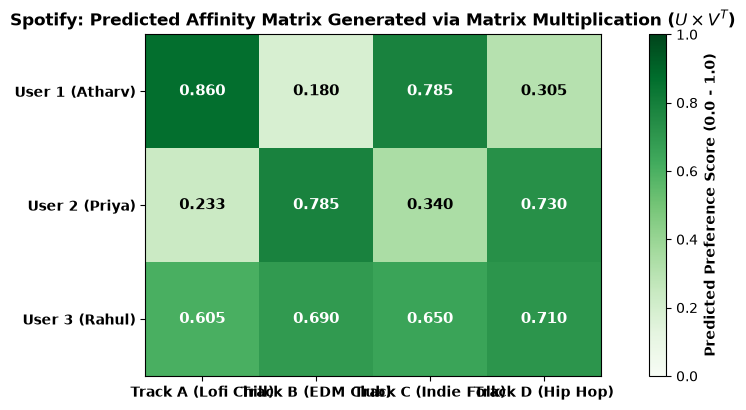

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Demonstration: Spotify Recommender Matrix Multiplication Simulation
# 3 Users (Atharv, Priya, Rahul) x 2 Latent Factors (Acoustic/Chill vs Electronic/Beats)
users = ["User 1 (Atharv)", "User 2 (Priya)", "User 3 (Rahul)"]
songs = ["Track A (Lofi Chill)", "Track B (EDM Club)", "Track C (Indie Folk)", "Track D (Hip Hop)"]

# U: User Embeddings (3 x 2)
U = np.array([
    [0.9, 0.1],  # Atharv loves acoustic/chill, dislikes high beats
    [0.2, 0.85], # Priya loves high beats, less chill
    [0.6, 0.7]   # Rahul likes a balanced mix of both
])

# V: Song Embeddings (4 x 2) -> V^T is (2 x 4)
V = np.array([
    [0.95, 0.05], # Track A: High chill, low beats
    [0.10, 0.90], # Track B: Low chill, high beats
    [0.85, 0.20], # Track C: High chill, moderate beats
    [0.25, 0.80]  # Track D: Moderate chill, high beats
])

# Matrix Multiplication: Predicted Affinity Matrix R_pred = U @ V.T (3 x 4)
R_pred = U @ V.T

df_spotify_rec = pd.DataFrame(
    np.round(R_pred, 3), 
    index=users, 
    columns=songs
)

print("=" * 72)
print("SPOTIFY COLLABORATIVE FILTERING: MATRIX MULTIPLICATION DEMO")
print("=" * 72)
print("Predicted User-Track Affinity Matrix (R = U x V^T):")
print(df_spotify_rec.to_string())
print("-" * 72)
for i, user in enumerate(users):
    best_song_idx = np.argmax(R_pred[i, :])
    best_score = R_pred[i, best_song_idx]
    print(f"  * Recommended for {user:<16} : '{songs[best_song_idx]}' (Score: {best_score:.3f})")
print("=" * 72)

# Heatmap Visualization
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(R_pred, cmap='Greens', vmin=0, vmax=1)
ax.set_xticks(range(len(songs)))
ax.set_yticks(range(len(users)))
ax.set_xticklabels(songs, fontsize=10, fontweight='bold')
ax.set_yticklabels(users, fontsize=10, fontweight='bold')
ax.set_title('Spotify: Predicted Affinity Matrix Generated via Matrix Multiplication ($U \\times V^T$)', 
             fontsize=12, fontweight='bold')

for i in range(len(users)):
    for j in range(len(songs)):
        val = R_pred[i, j]
        color = 'white' if val > 0.6 else 'black'
        ax.text(j, i, f'{val:.3f}', ha='center', va='center', color=color, fontsize=11, fontweight='bold')

cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Predicted Preference Score (0.0 - 1.0)', fontweight='bold')

plt.tight_layout()
plt.show()



## Summary & Key Coursework Takeaways

| Task / Topic | Mathematical Formula | Core Operation / Function | Practical Data Science Takeaway |
| :--- | :--- | :--- | :--- |
| **Task 1: Matrix Multiplication** | $C_{i,j} = \sum_k A_{i,k} B_{k,j}$ | `A @ B` (NumPy Matrix Dot) | Transforms engagement features into weighted composite revenue/reach scores. |
| **Task 2: Prediction Function** | $y = mx + c$ | `linear_regression_predict(x, m, c)` | Encapsulates univariate linear prediction supporting both scalars and batch numpy arrays. |
| **Task 3: Zomato Delivery** | $y = 4x + 10$ | $x \in \{2, 5, 8\} \to y = \{18, 30, 42\}$ mins | Slope is travel speed ($4\text{ min/km}$); Intercept is fixed kitchen prep time ($10\text{ mins}$). |
| **Task 4: Flipkart Intuition** | $\text{Price} = m(\text{Rating}) + c$ | Slope: $\frac{\Delta y}{\Delta x}$, Intercept: Baseline Floor | Slope captures brand equity/willingness to pay; Intercept captures base manufacturing costs. |
| **Task 5: Spotify Recommender** | $R_{M \times N} \approx U_{M \times K} V^T_{K \times N}$ | Low-Rank Matrix Factorization | Reconstructs affinity across millions of users/songs via parallelized GPU matrix products. |

---
*Assignment complete and executed in compliance with Data Science coursework requirements.*
